In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/stats_player_reg_2026.csv")

print(df.shape)
print(df.columns.tolist())

(1807, 148)
['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'season_type', 'recent_team', 'games', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receiving_20', 

In [2]:
print(df["position"].value_counts())

position
LB     267
WR     229
CB     179
DT     150
RB     148
SAF    136
TE     127
DE     112
OT      97
G       79
QB      70
K       38
DB      37
C       36
P       34
LS      22
OLB     10
FS       9
FB       7
MLB      5
S        4
DL       4
NT       3
ILB      3
Name: count, dtype: int64


In [3]:
qb_df = df[df["position"] == "QB"].copy()

print(qb_df.shape)

(70, 148)


In [4]:
qb_df.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,season_type,recent_team,games,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,PIT,9,...,0,0,0,0,0,0,0,0,132.76,132.76
3,00-0026498,M.Stafford,Matthew Stafford,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,LA,10,...,0,0,0,0,0,0,0,0,162.62,162.62
9,00-0027973,A.Dalton,Andy Dalton,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,PHI,1,...,0,0,0,0,0,0,0,0,-2.00,-2.00
10,00-0028118,T.Taylor,Tyrod Taylor,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,GB,2,...,0,0,0,0,0,0,0,0,-0.08,-0.08
13,00-0028986,C.Keenum,Case Keenum,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,CHI,2,...,0,0,0,0,0,0,0,0,25.20,25.20


In [5]:
for col in qb_df.columns:
    if "win" in col.lower():
        print(col)

In [6]:
for col in qb_df.columns:
    if "loss" in col.lower():
        print(col)

def_tackles_for_loss
def_tackles_for_loss_yards


In [7]:
qb_df = qb_df.sort_values(
    by="passing_yards",
    ascending=False
)

qb_df[
    [
        "player_display_name",
        "recent_team",
        "games",
        "passing_yards",
        "passing_tds",
        "passing_interceptions",
        "passing_epa",
        "passing_cpoe"
    ]
].head(15)

,player_display_name,recent_team,games,passing_yards,passing_tds,passing_interceptions,passing_epa,passing_cpoe
444,Jordan Love,GB,10,2838,20,7,55.813423,0.990165
514,Joe Burrow,CIN,9,2795,27,6,96.354470,10.534886
104,Dak Prescott,DAL,10,2724,21,6,63.602024,-0.133117
3,Matthew Stafford,LA,10,2623,19,10,46.007956,0.413497
14,Kirk Cousins,MIN,10,2547,22,9,54.036317,0.249250
1072,C.J. Stroud,HOU,9,2462,19,3,45.020180,0.853300
108,Jared Goff,DET,9,2437,18,4,64.310526,0.795071
1068,Bryce Young,CAR,9,2397,16,6,15.589684,0.214727
160,Patrick Mahomes,KC,9,2385,19,4,48.005213,1.911001
820,Brock Purdy,SF,9,2369,20,5,84.111358,5.431691


In [8]:
qb_df["completion_pct"] = (
    qb_df["completions"] /
    qb_df["attempts"]
) * 100

In [9]:
qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

In [10]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "completion_pct",
        "td_int_ratio"
    ]
].head()

,player_display_name,recent_team,completion_pct,td_int_ratio
444,Jordan Love,GB,63.043478,2.857143
514,Joe Burrow,CIN,74.705882,4.500000
104,Dak Prescott,DAL,64.082687,3.500000
3,Matthew Stafford,LA,66.666667,1.900000
14,Kirk Cousins,MIN,64.450867,2.444444


In [12]:
qb_df["completion_pct"] = (
    qb_df["completions"] /
    qb_df["attempts"]
) * 100

qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

qb_df["yards_per_attempt"] = (
    qb_df["passing_yards"] /
    qb_df["attempts"]
)

In [13]:
qb_df[
    [
        "player_display_name",
        "passing_tds",
        "passing_interceptions",
        "td_int_ratio"
    ]
].sort_values(
    by="td_int_ratio",
    ascending=False
).head(15)

,player_display_name,passing_tds,passing_interceptions,td_int_ratio
70,Marcus Mariota,4,0,inf
1516,Shedeur Sanders,2,0,inf
1461,DJ Uiagalelei,1,0,inf
327,Gardner Minshew,3,0,inf
1528,Jaxson Dart,3,0,inf
382,Drew Lock,7,0,inf
1072,C.J. Stroud,19,3,6.333333
257,Lamar Jackson,6,1,6.000000
1286,Jayden Daniels,10,2,5.000000
160,Patrick Mahomes,19,4,4.750000


In [14]:
metrics = [
    "completion_pct",
    "passing_yards",
    "passing_tds",
    "passing_interceptions",
    "passing_epa",
    "passing_cpoe",
    "yards_per_attempt",
    "td_int_ratio"
]

corr_matrix = qb_df[metrics].corr()

corr_matrix

,completion_pct,passing_yards,passing_tds,passing_interceptions,passing_epa,passing_cpoe,yards_per_attempt,td_int_ratio
completion_pct,1.000000,0.245590,0.239115,0.106799,0.252696,0.948622,0.634138,0.430136
passing_yards,0.245590,1.000000,0.947201,0.793830,0.571205,0.367768,0.458089,0.606244
passing_tds,0.239115,0.947201,1.000000,0.685820,0.736904,0.348735,0.444285,0.684449
passing_interceptions,0.106799,0.793830,0.685820,1.000000,0.129541,0.203226,0.255720,-0.035551
passing_epa,0.252696,0.571205,0.736904,0.129541,1.000000,0.306220,0.446870,0.673790
passing_cpoe,0.948622,0.367768,0.348735,0.203226,0.306220,1.000000,0.684812,0.517881
yards_per_attempt,0.634138,0.458089,0.444285,0.255720,0.446870,0.684812,1.000000,0.475434
td_int_ratio,0.430136,0.606244,0.684449,-0.035551,0.673790,0.517881,0.475434,1.000000


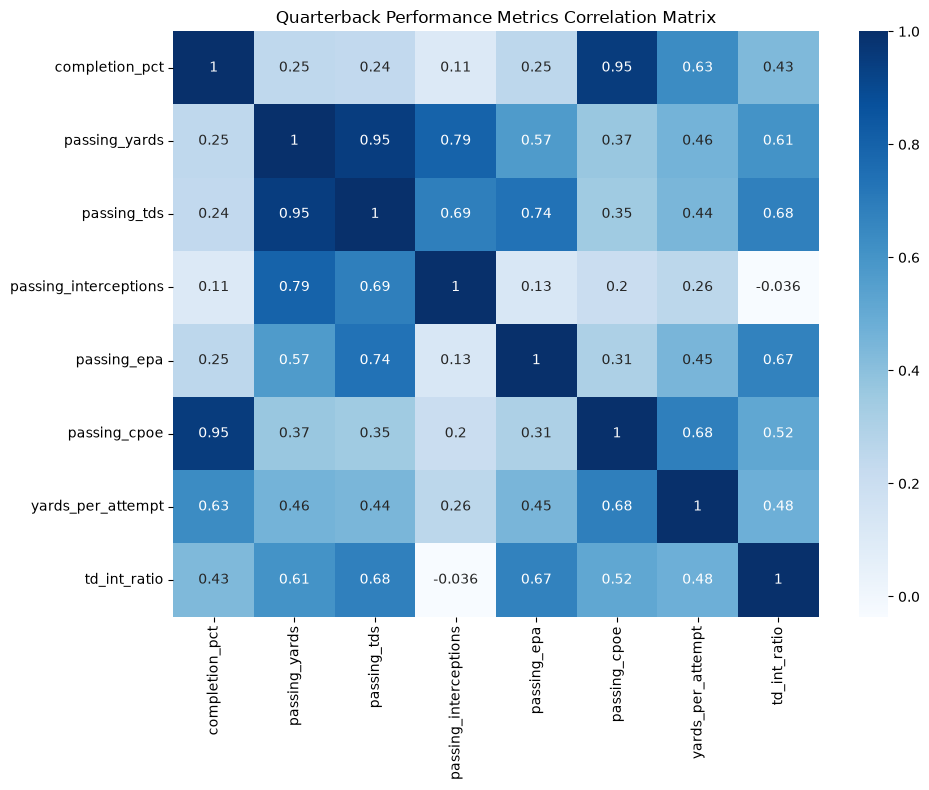

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues"
)

plt.title("Quarterback Performance Metrics Correlation Matrix")

plt.tight_layout()
plt.show()

In [16]:
import numpy as np

qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

qb_df["td_int_ratio"] = (
    qb_df["td_int_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

In [17]:
qb_df[
    [
        "player_display_name",
        "passing_tds",
        "passing_interceptions",
        "td_int_ratio"
    ]
].sort_values(
    by="td_int_ratio",
    ascending=False
).head(15)

,player_display_name,passing_tds,passing_interceptions,td_int_ratio
1072,C.J. Stroud,19,3,6.333333
257,Lamar Jackson,6,1,6.000000
1286,Jayden Daniels,10,2,5.000000
160,Patrick Mahomes,19,4,4.750000
108,Jared Goff,18,4,4.500000
514,Joe Burrow,27,6,4.500000
630,Trevor Lawrence,21,5,4.200000
820,Brock Purdy,20,5,4.000000
29,Geno Smith,12,3,4.000000
403,Tyler Huntley,4,1,4.000000


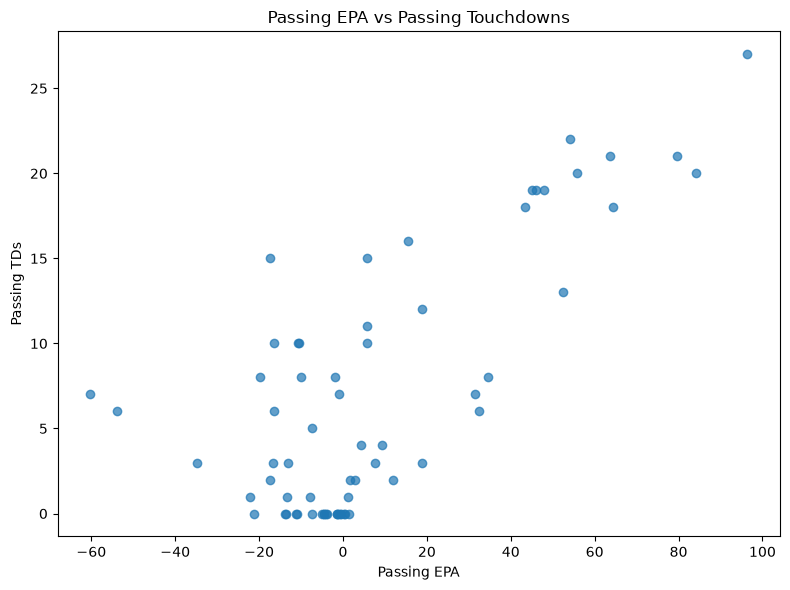

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    qb_df["passing_epa"],
    qb_df["passing_tds"],
    alpha=0.7
)

plt.xlabel("Passing EPA")
plt.ylabel("Passing TDs")
plt.title("Passing EPA vs Passing Touchdowns")

plt.tight_layout()
plt.show()

In [19]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "passing_epa",
        "passing_cpoe",
        "passing_tds",
        "passing_interceptions"
    ]
].sort_values(
    by="passing_epa",
    ascending=False
).head(15)

,player_display_name,recent_team,passing_epa,passing_cpoe,passing_tds,passing_interceptions
514,Joe Burrow,CIN,96.354470,10.534886,27,6
820,Brock Purdy,SF,84.111358,5.431691,20,5
630,Trevor Lawrence,JAX,79.744210,4.183893,21,5
108,Jared Goff,DET,64.310526,0.795071,18,4
104,Dak Prescott,DAL,63.602024,-0.133117,21,6
444,Jordan Love,GB,55.813423,0.990165,20,7
14,Kirk Cousins,MIN,54.036317,0.249250,22,9
277,Josh Allen,BUF,52.543438,2.747870,13,7
160,Patrick Mahomes,KC,48.005213,1.911001,19,4
3,Matthew Stafford,LA,46.007956,0.413497,19,10


In [20]:
qb_df["qb_score"] = (
    (qb_df["passing_epa"] * 0.4)
    +
    (qb_df["passing_cpoe"] * 0.2)
    +
    (qb_df["td_int_ratio"] * 10 * 0.2)
    +
    (qb_df["yards_per_attempt"] * 5 * 0.2)
)

In [21]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score",
        "passing_epa",
        "passing_tds",
        "passing_interceptions"
    ]
].sort_values(
    by="qb_score",
    ascending=False
).head(15)

,player_display_name,recent_team,qb_score,passing_epa,passing_tds,passing_interceptions
514,Joe Burrow,CIN,57.869354,96.354470,27,6
820,Brock Purdy,SF,51.704366,84.111358,20,5
630,Trevor Lawrence,JAX,49.952995,79.744210,21,5
108,Jared Goff,DET,42.899672,64.310526,18,4
104,Dak Prescott,DAL,39.452946,63.602024,21,6
1072,C.J. Stroud,HOU,38.539149,45.020180,19,3
160,Patrick Mahomes,KC,37.087641,48.005213,19,4
257,Lamar Jackson,BAL,36.451361,32.517411,6,1
444,Jordan Love,GB,35.949645,55.813423,20,7
277,Josh Allen,BUF,33.931040,52.543438,13,7


In [22]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score"
    ]
].sort_values(
    by="qb_score",
    ascending=False
)

,player_display_name,recent_team,qb_score
514,Joe Burrow,CIN,57.869354
820,Brock Purdy,SF,51.704366
630,Trevor Lawrence,JAX,49.952995
108,Jared Goff,DET,42.899672
104,Dak Prescott,DAL,39.452946
...,...,...,...
250,Mason Rudolph,PIT,NaN
631,Mac Jones,SF,NaN
622,Justin Fields,KC,NaN
129,Nick Mullens,JAX,NaN


In [30]:
qb_df["qb_tier"] = pd.qcut(
    qb_df["qb_score"],
    q=4,
    labels=[
        "Tier 4",
        "Tier 3",
        "Tier 2",
        "Tier 1"
    ]
)

qb_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score",
        "qb_tier"
    ]
].sort_values(
    by="qb_score",
    ascending=False
)

,player_display_name,recent_team,qb_score,qb_tier
514,Joe Burrow,CIN,57.869354,Tier 1
820,Brock Purdy,SF,51.704366,Tier 1
630,Trevor Lawrence,JAX,49.952995,Tier 1
108,Jared Goff,DET,42.899672,Tier 1
104,Dak Prescott,DAL,39.452946,Tier 1
...,...,...,...,...
250,Mason Rudolph,PIT,NaN,NaN
631,Mac Jones,SF,NaN,NaN
622,Justin Fields,KC,NaN,NaN
129,Nick Mullens,JAX,NaN,NaN


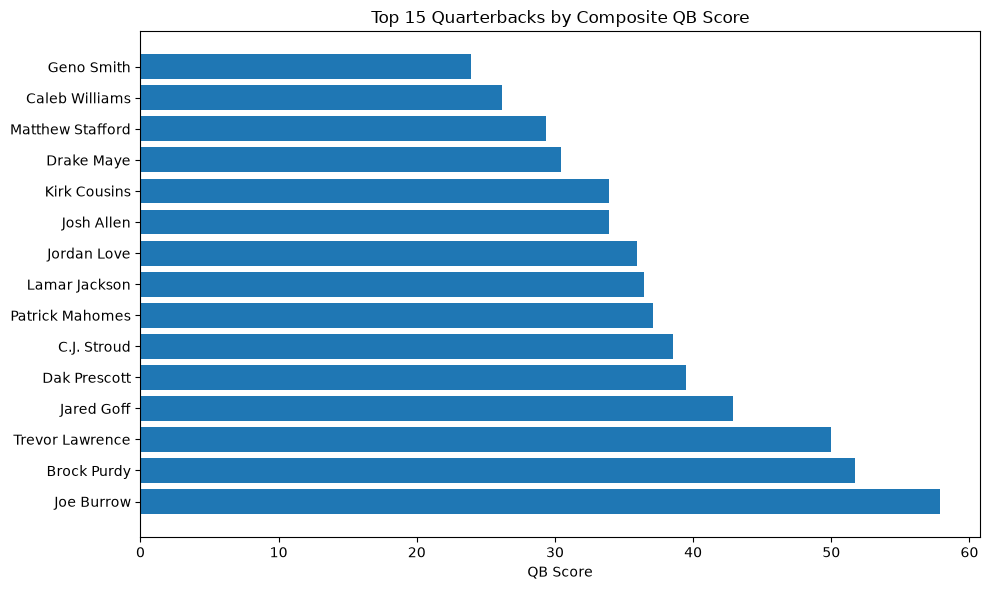

In [24]:
import matplotlib.pyplot as plt

top_15 = qb_df.sort_values(
    by="qb_score",
    ascending=False
).head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_15["player_display_name"],
    top_15["qb_score"]
)

plt.title("Top 15 Quarterbacks by Composite QB Score")
plt.xlabel("QB Score")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_qb_scores.png",
    bbox_inches="tight"
)

plt.show()

In [25]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "passing_yards",
        "passing_tds",
        "passing_interceptions",
        "passing_epa",
        "passing_cpoe",
        "qb_score"
    ]
].sort_values(
    by="passing_yards",
    ascending=False
).head(15)

,player_display_name,recent_team,passing_yards,passing_tds,passing_interceptions,passing_epa,passing_cpoe,qb_score
444,Jordan Love,GB,2838,20,7,55.813423,0.990165,35.949645
514,Joe Burrow,CIN,2795,27,6,96.354470,10.534886,57.869354
104,Dak Prescott,DAL,2724,21,6,63.602024,-0.133117,39.452946
3,Matthew Stafford,LA,2623,19,10,46.007956,0.413497,29.336957
14,Kirk Cousins,MIN,2547,22,9,54.036317,0.249250,33.914537
1072,C.J. Stroud,HOU,2462,19,3,45.020180,0.853300,38.539149
108,Jared Goff,DET,2437,18,4,64.310526,0.795071,42.899672
1068,Bryce Young,CAR,2397,16,6,15.589684,0.214727,18.703868
160,Patrick Mahomes,KC,2385,19,4,48.005213,1.911001,37.087641
820,Brock Purdy,SF,2369,20,5,84.111358,5.431691,51.704366


In [26]:
qb_df[
    [
        "player_display_name",
        "passing_epa",
        "passing_cpoe",
        "td_int_ratio",
        "yards_per_attempt"
    ]
].isnull().sum()

player_display_name     0
passing_epa             4
passing_cpoe            4
td_int_ratio           22
yards_per_attempt       4
dtype: int64

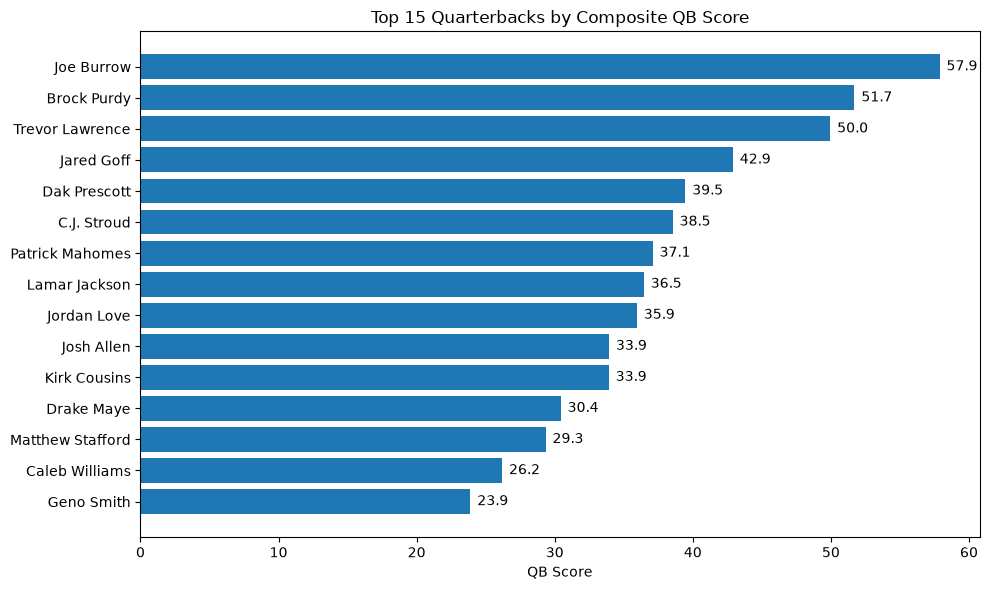

In [27]:
top_15 = (
    qb_df
    .sort_values(by="qb_score", ascending=False)
    .head(15)
    .sort_values(by="qb_score")
)

plt.figure(figsize=(10,6))

bars = plt.barh(
    top_15["player_display_name"],
    top_15["qb_score"]
)

plt.title("Top 15 Quarterbacks by Composite QB Score")
plt.xlabel("QB Score")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "../visualizations/top_qb_scores.png",
    bbox_inches="tight"
)

plt.show()

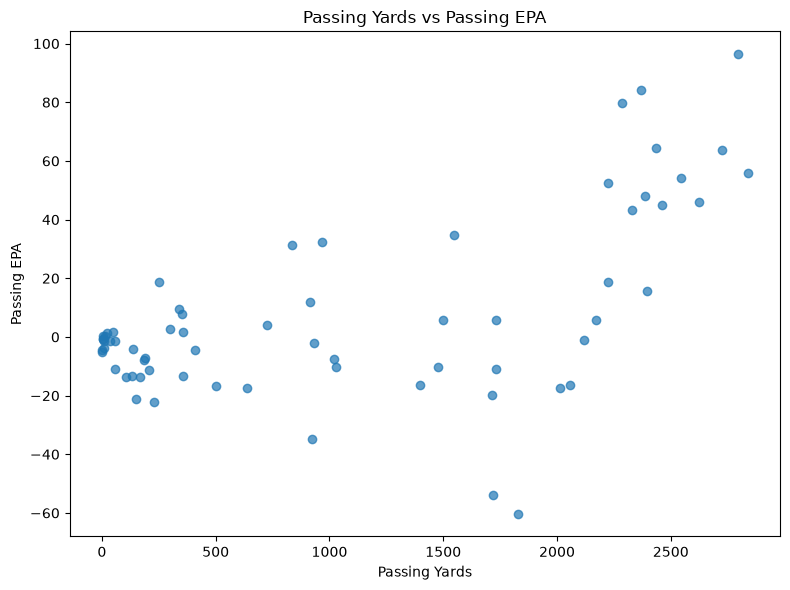

In [28]:
plt.figure(figsize=(8,6))

plt.scatter(
    qb_df["passing_yards"],
    qb_df["passing_epa"],
    alpha=0.7
)

plt.xlabel("Passing Yards")
plt.ylabel("Passing EPA")
plt.title("Passing Yards vs Passing EPA")

plt.tight_layout()
plt.show()

In [31]:
import numpy as np

qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

qb_df["td_int_ratio"] = (
    qb_df["td_int_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

qb_df["td_int_ratio"] = qb_df["td_int_ratio"].fillna(0)

qb_df["passing_epa"] = qb_df["passing_epa"].fillna(0)
qb_df["passing_cpoe"] = qb_df["passing_cpoe"].fillna(0)
qb_df["yards_per_attempt"] = qb_df["yards_per_attempt"].fillna(0)

In [32]:
qb_df["qb_tier"] = pd.qcut(
    qb_df["qb_score"],
    q=4,
    labels=[
        "Tier 4",
        "Tier 3",
        "Tier 2",
        "Tier 1"
    ]
)

qb_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score",
        "qb_tier"
    ]
].sort_values(
    by="qb_score",
    ascending=False
)

,player_display_name,recent_team,qb_score,qb_tier
514,Joe Burrow,CIN,57.869354,Tier 1
820,Brock Purdy,SF,51.704366,Tier 1
630,Trevor Lawrence,JAX,49.952995,Tier 1
108,Jared Goff,DET,42.899672,Tier 1
104,Dak Prescott,DAL,39.452946,Tier 1
...,...,...,...,...
250,Mason Rudolph,PIT,NaN,NaN
631,Mac Jones,SF,NaN,NaN
622,Justin Fields,KC,NaN,NaN
129,Nick Mullens,JAX,NaN,NaN


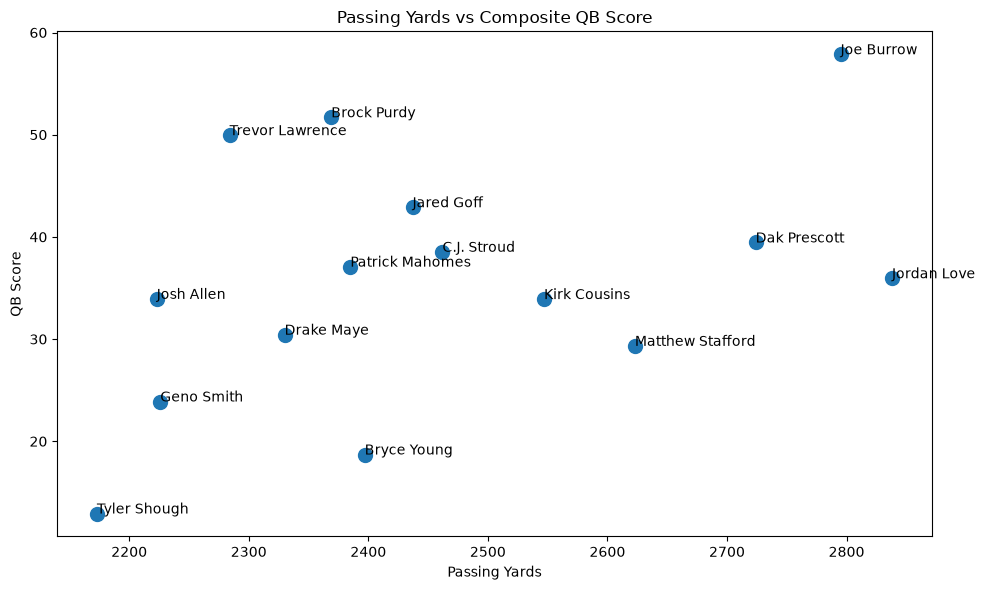

In [33]:
plt.figure(figsize=(10,6))

top_15 = qb_df.sort_values(
    by="passing_yards",
    ascending=False
).head(15)

plt.scatter(
    top_15["passing_yards"],
    top_15["qb_score"],
    s=100
)

for _, row in top_15.iterrows():
    plt.annotate(
        row["player_display_name"],
        (row["passing_yards"], row["qb_score"])
    )

plt.xlabel("Passing Yards")
plt.ylabel("QB Score")
plt.title("Passing Yards vs Composite QB Score")

plt.tight_layout()
plt.show()


In [34]:
team_df = pd.read_csv(
    "../data/raw/stats_team_reg_2026.csv"
)

print(team_df.shape)

print(team_df.columns.tolist())

(32, 136)
['season', 'team', 'season_type', 'games', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receiving_20', 'receiving_40', 'special_teams_tds', 'def_tackles_solo', 'def_tackles_with_assist', 'def_tackle_assists', 'def_tac

In [35]:
team_stats = team_df[
    [
        "team",
        "passing_epa",
        "passing_cpoe",
        "sacks_suffered",
        "passing_yards",
        "passing_tds"
    ]
]

team_stats.head()

,team,passing_epa,passing_cpoe,sacks_suffered,passing_yards,passing_tds
0,ARI,-23.093165,0.555251,28,2188,13
1,ATL,-45.370057,-7.387313,19,2052,11
2,BAL,16.558363,1.820790,25,2182,10
3,BUF,52.543438,2.747870,18,2223,13
4,CAR,17.128245,0.056071,29,2444,16


In [36]:
merged_df = qb_df.merge(
    team_stats,
    left_on="recent_team",
    right_on="team",
    suffixes=(
        "_qb",
        "_team"
    )
)

print(merged_df.shape)

(70, 159)


In [37]:
merged_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score",
        "sacks_suffered"
    ]
].sort_values(
    by="qb_score",
    ascending=False
)

KeyError: "['sacks_suffered'] not in index"

In [38]:
print(merged_df.columns.tolist())


['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'season_type', 'recent_team', 'games', 'completions', 'attempts', 'passing_yards_qb', 'passing_tds_qb', 'passing_interceptions', 'sacks_suffered_qb', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa_qb', 'passing_cpoe_qb', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receiving_20

In [39]:
merged_df[
    [
        "player_display_name",
        "recent_team",
        "qb_score",
        "sacks_suffered_team"
    ]
].sort_values(
    by="qb_score",
    ascending=False
).head(20)

,player_display_name,recent_team,qb_score,sacks_suffered_team
1,Joe Burrow,CIN,57.869354,16
9,Brock Purdy,SF,51.704366,13
11,Trevor Lawrence,JAX,49.952995,14
6,Jared Goff,DET,42.899672,21
2,Dak Prescott,DAL,39.452946,15
5,C.J. Stroud,HOU,38.539149,17
8,Patrick Mahomes,KC,37.087641,12
29,Lamar Jackson,BAL,36.451361,25
0,Jordan Love,GB,35.949645,25
13,Josh Allen,BUF,33.931040,18


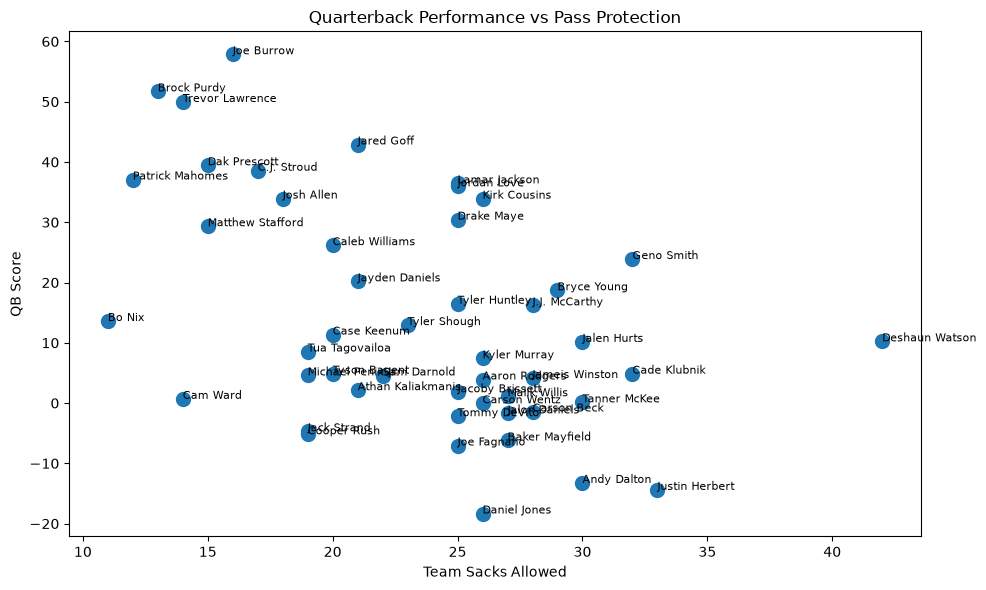

In [40]:
plt.figure(figsize=(10,6))

plt.scatter(
    merged_df["sacks_suffered_team"],
    merged_df["qb_score"],
    s=100
)

for _, row in merged_df.iterrows():
    plt.annotate(
        row["player_display_name"],
        (
            row["sacks_suffered_team"],
            row["qb_score"]
        ),
        fontsize=8
    )

plt.xlabel("Team Sacks Allowed")
plt.ylabel("QB Score")
plt.title("Quarterback Performance vs Pass Protection")

plt.tight_layout()

plt.savefig(
    "../visualizations/qb_score_vs_protection.png",
    bbox_inches="tight"
)

plt.show()


In [41]:
merged_df[
    [
        "qb_score",
        "sacks_suffered_team"
    ]
].corr()

,qb_score,sacks_suffered_team
qb_score,1.000000,-0.466497
sacks_suffered_team,-0.466497,1.000000


In [42]:
[w for w in team_df.columns if "win" in w.lower()]

[]

In [43]:
[w for w in team_df.columns if "loss" in w.lower()]

['def_tackles_for_loss', 'def_tackles_for_loss_yards']

In [44]:
qb_df["epa_per_game"] = (
    qb_df["passing_epa"] /
    qb_df["games"]
)

qb_df["yards_per_game"] = (
    qb_df["passing_yards"] /
    qb_df["games"]
)

qb_df["tds_per_game"] = (
    qb_df["passing_tds"] /
    qb_df["games"]
)

qb_df["ints_per_game"] = (
    qb_df["passing_interceptions"] /
    qb_df["games"]
)

In [45]:
qb_df["qb_score_v2"] = (
    qb_df["epa_per_game"] * 0.4
    +
    qb_df["passing_cpoe"] * 0.2
    +
    qb_df["td_int_ratio"] * 2 * 0.2
    +
    qb_df["yards_per_attempt"] * 0.2
)

In [46]:
qualified_qbs = qb_df[qb_df["games"] >= 5].copy()

In [47]:
qualified_qbs = qb_df[qb_df["games"] >= 5].copy()

qualified_qbs["epa_per_game"] = (
    qualified_qbs["passing_epa"] /
    qualified_qbs["games"]
)

qualified_qbs[
    [
        "player_display_name",
        "recent_team",
        "games",
        "passing_epa",
        "epa_per_game"
    ]
].sort_values(
    by="epa_per_game",
    ascending=False
).head(15)

,player_display_name,recent_team,games,passing_epa,epa_per_game
514,Joe Burrow,CIN,9,96.354470,10.706052
820,Brock Purdy,SF,9,84.111358,9.345706
630,Trevor Lawrence,JAX,9,79.744210,8.860468
108,Jared Goff,DET,9,64.310526,7.145614
257,Lamar Jackson,BAL,5,32.517411,6.503482
104,Dak Prescott,DAL,10,63.602024,6.360202
277,Josh Allen,BUF,9,52.543438,5.838160
1292,Caleb Williams,CHI,6,34.643136,5.773856
444,Jordan Love,GB,10,55.813423,5.581342
14,Kirk Cousins,MIN,10,54.036317,5.403632
